# Notebook 2: export the SVI grids

Aggregates the labelled street networks around the six sensors and the two EPA stations onto the
extended grid from notebook 1, using `aggregate_tagged_network_over_grid` in
`src/kriging/network_grid_aggregation.py`.

The features are the ones the inference models require: `gvi`, `facade_area`, `n_cars`,
`sky_ratio`, `road_ratio`. They come from `built_environment_features_pre_counts.csv`, which holds
the same definitions used to train those models. No log transform is applied to the counts here.

This notebook runs on the `alivestreets` kernel because it rebuilds the samplers with
`StreetSampler`. Notebook 1 runs on `base` because the satellite extractors need
`planetary-computer`, `pystac-client`, `stackstac` and `rasterio`, which the alivestreets
environment does not carry.

You get a lot of None because there is space for which we do not have a labelled network and that
is ok, those cells are not of interest.

## Cell 1: Open the extended grid and the point features

In [1]:
from pathlib import Path
import sys

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.kriging.network_grid_aggregation import aggregate_tagged_network_over_grid

NOTEBOOK_FOLDER_NAME = "2026_09_17_create_epa_vectors_for_inference"
PARENT_PATH_DATA = PROJECT_ROOT/"data"/NOTEBOOK_FOLDER_NAME
PARENT_PATH_SITES = PROJECT_ROOT/"data"/"2026_09_16_site_built_environment_comparison"

PATH_EXTENDED_GRID = PARENT_PATH_DATA/"grid_rectangles_extended.geojson"
PATH_POINT_FEATURES = PARENT_PATH_DATA/"built_environment_features_pre_counts.csv"

MODEL_FEATURES = ["gvi", "facade_area", "n_cars", "sky_ratio", "road_ratio"]

extended_grid = gpd.read_file(PATH_EXTENDED_GRID)
point_features = pd.read_csv(PATH_POINT_FEATURES)

print(f"grid cells: {len(extended_grid)}   crs: {extended_grid.crs}")
print(f"point features: {len(point_features)} rows over {point_features['site_name'].nunique()} sites")
print(f"model features present: {[f for f in MODEL_FEATURES if f in point_features.columns]}")
print(point_features.groupby("site_name").size().to_string())

grid cells: 2806   crs: EPSG:26986
point features: 4625 rows over 8 sites
model features present: ['gvi', 'facade_area', 'n_cars', 'sky_ratio', 'road_ratio']
site_name
Carter Field                   563
Carter Field — 2               587
DUDLEY SQUARE ROXBURY          577
Gainsborough Parking Garage    592
Robinson Hall                  619
VON HILLERN ST                 314
West Village B                 689
World Series Way               684


## Cell 2: Tag each site network with the model features

In [2]:
from alivestreets.sampling.street_sampler import StreetSampler
from alivestreets.sampling.geojson_sampler_exporter import StreetSamplerGeojsonExporter
from tqdm import tqdm

N_SAMPLING_POINTS = 300
COORDINATE_TOLERANCE = 1e-6

PARENT_PATH_TAGGED = PARENT_PATH_DATA/"tagged_networks"
PARENT_PATH_TAGGED.mkdir(parents = True, exist_ok = True)

site_names = sorted(point_features["site_name"].unique())
site_name_to_tagged_path = {}

for site_name in tqdm(site_names):
    site_point_features = point_features[point_features["site_name"] == site_name].sort_values("point_index")

    sampler = StreetSampler(N_SAMPLING_POINTS)
    sampler.open_streets(str(PARENT_PATH_SITES/site_name/"network.geojson"))
    sampler.sample_streets_no_intersections()

    sampling_points = sampler.get_all_sampling_points()
    if len(sampling_points) != len(site_point_features):
        raise SystemExit(f"{site_name}: {len(sampling_points)} sampling points against {len(site_point_features)} rows")

    largest_difference = 0.0
    for (longitude, latitude), (_, row) in zip(sampling_points, site_point_features.iterrows()):
        largest_difference = max(largest_difference, abs(longitude - row["longitude"]), abs(latitude - row["latitude"]))
    if largest_difference > COORDINATE_TOLERANCE:
        raise SystemExit(f"{site_name}: sampling points do not match the feature rows ({largest_difference})")

    for feature_name in MODEL_FEATURES:
        values = [None if pd.isna(value) else float(value) for value in site_point_features[feature_name]]
        sampler.tag_streets(feature_name, values, method = "mean")

    tagged_path = PARENT_PATH_TAGGED/f"{site_name.strip().replace(' ', '_')}.geojson"
    StreetSamplerGeojsonExporter(sampler).export(str(tagged_path))
    site_name_to_tagged_path[site_name] = tagged_path

    print(f"{site_name}: {len(sampler.streets)} streets, {len(sampling_points)} points -> {tagged_path.name}")

 12%|█▎        | 1/8 [00:00<00:01,  3.85it/s]

Carter Field: 486 streets, 563 points -> Carter_Field.geojson


 25%|██▌       | 2/8 [00:00<00:01,  3.96it/s]

Carter Field — 2: 534 streets, 587 points -> Carter_Field_—_2.geojson


 38%|███▊      | 3/8 [00:00<00:01,  4.07it/s]

DUDLEY SQUARE ROXBURY: 506 streets, 577 points -> DUDLEY_SQUARE_ROXBURY.geojson


... (4 outputs left out)

 88%|████████▊ | 7/8 [00:01<00:00,  4.09it/s]

West Village B: 641 streets, 689 points -> West_Village_B.geojson


100%|██████████| 8/8 [00:02<00:00,  3.95it/s]

World Series Way : 634 streets, 684 points -> World_Series_Way.geojson


## Cell 3: Aggregate the tagged networks over the extended grid and export one geojson per feature

In [3]:
tagged_networks = []
for site_name, tagged_path in site_name_to_tagged_path.items():
    tagged_network = gpd.read_file(tagged_path)
    tagged_network["site_name"] = site_name
    tagged_networks.append(tagged_network)

all_tagged_networks = gpd.GeoDataFrame(
    pd.concat(tagged_networks, ignore_index = True),
    geometry = "geometry",
    crs = tagged_networks[0].crs
)

print(f"tagged street rows: {len(all_tagged_networks)}   crs: {all_tagged_networks.crs}")
print(f"columns: {list(all_tagged_networks.columns)}")

grid_aggregated_by_feature = aggregate_tagged_network_over_grid(
    all_tagged_networks,
    extended_grid,
    MODEL_FEATURES
)

for feature_name, feature_grid in grid_aggregated_by_feature.items():
    output_path = PARENT_PATH_DATA/f"grid_aggregated_{feature_name}.geojson"
    feature_grid.to_file(output_path, driver = "GeoJSON")
    n_filled = int(feature_grid[f"{feature_name}_mean"].notna().sum())
    print(f"{feature_name}: {n_filled} of {len(feature_grid)} cells have a value -> {output_path.name}")

tagged street rows: 5172   crs: EPSG:4326
columns: ['name', 'length', 'gvi', 'facade_area', 'n_cars', 'sky_ratio', 'road_ratio', 'geometry', 'site_name']
gvi: 441 of 2806 cells have a value -> grid_aggregated_gvi.geojson
facade_area: 441 of 2806 cells have a value -> grid_aggregated_facade_area.geojson
n_cars: 441 of 2806 cells have a value -> grid_aggregated_n_cars.geojson
sky_ratio: 441 of 2806 cells have a value -> grid_aggregated_sky_ratio.geojson
road_ratio: 441 of 2806 cells have a value -> grid_aggregated_road_ratio.geojson


## Cell 4: Look at the coverage

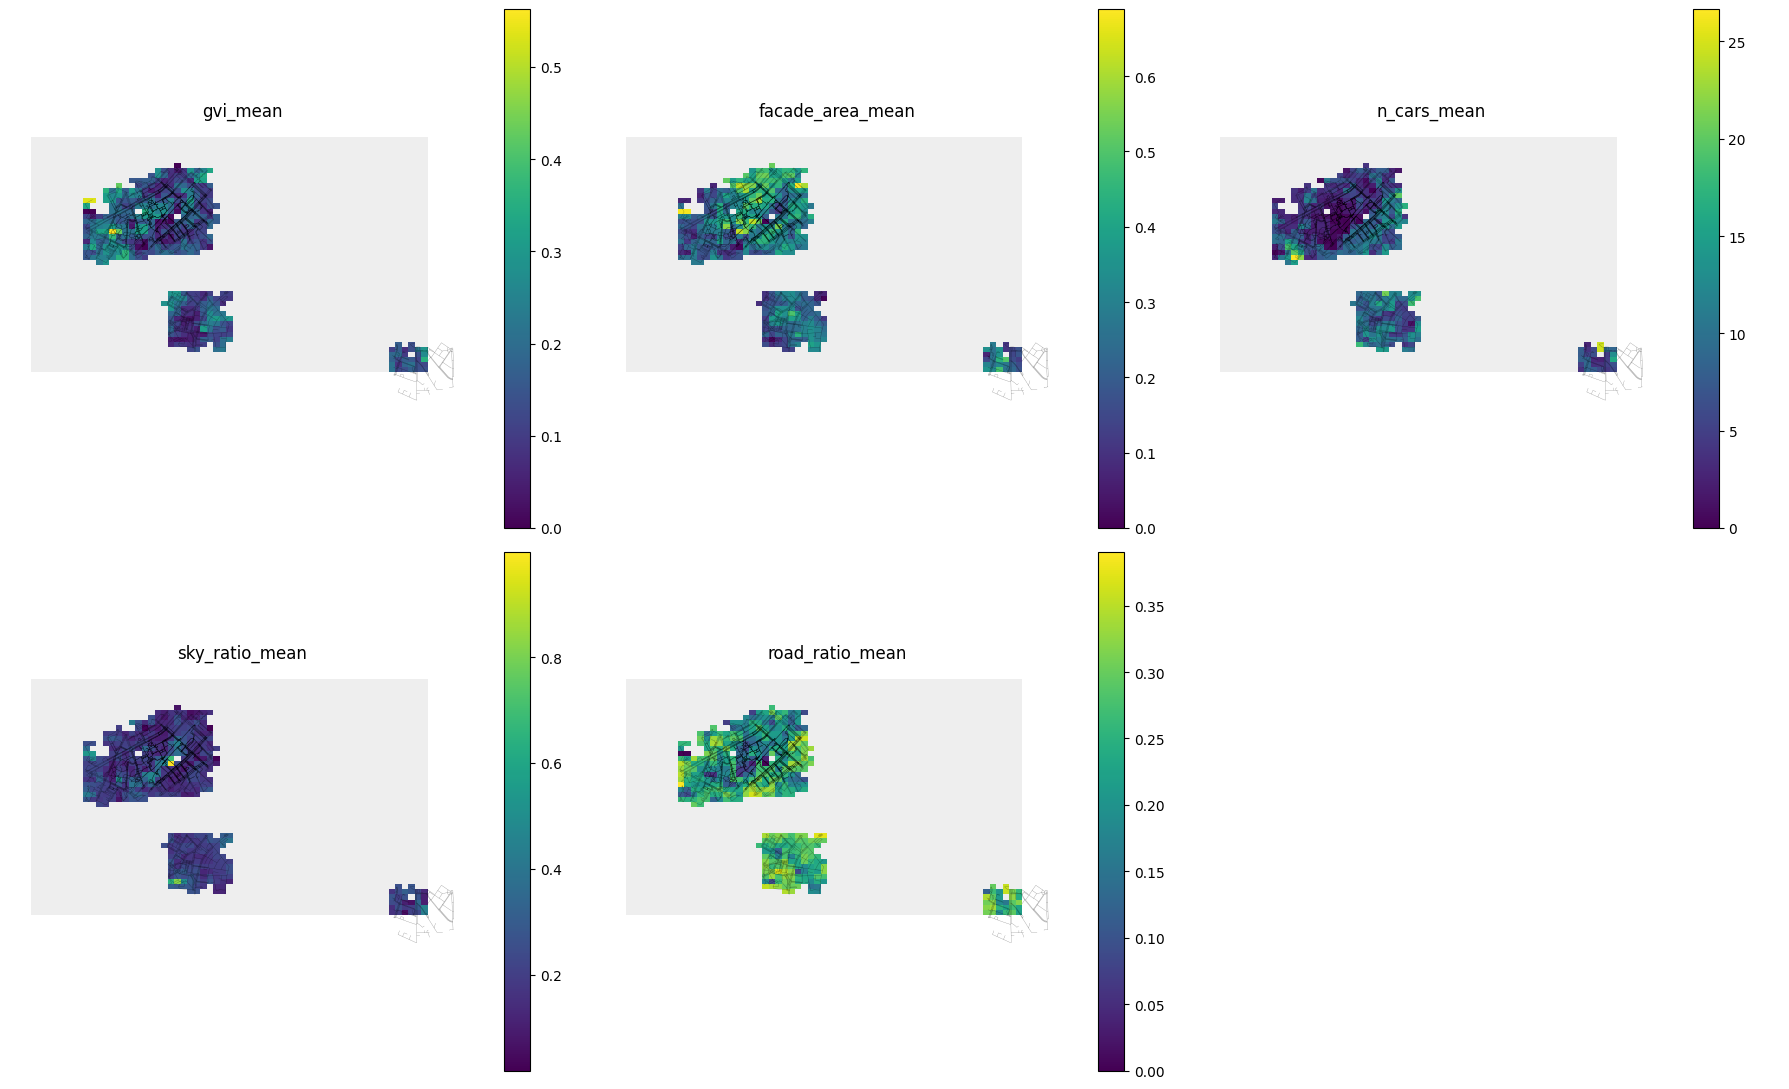

In [4]:
fig, axes = plt.subplots(2, 3, figsize = (18, 11))
axes = np.array(axes).flatten()

for ax, feature_name in zip(axes, MODEL_FEATURES):
    feature_grid = grid_aggregated_by_feature[feature_name]
    feature_grid.plot(
        column = f"{feature_name}_mean",
        ax = ax,
        cmap = "viridis",
        legend = True,
        edgecolor = "none",
        missing_kwds = {"color": "#EEEEEE"}
    )
    all_tagged_networks.to_crs(extended_grid.crs).plot(ax = ax, color = "black", linewidth = 0.2, alpha = 0.5)
    ax.set_title(f"{feature_name}_mean")
    ax.set_axis_off()

for ax in axes[len(MODEL_FEATURES):]:
    ax.axis("off")

plt.tight_layout()
plt.show()